# Illustration of the beta computation (one V1 vertex)

Step-by-step illustration of `make_od_img.py` on real data: one amblyope, one V1 vertex with a good pRF fit in **both** eyes.

1. Data and pRF fit of each eye
2. The two pRF predictions have arbitrary scales
3. Each prediction is z-scored once on the whole concatenation
4. Their mean = common regressor (its mean differs from run to run)
5. One baseline per run: run mean removed from the regressor and from the data
6. GLM of each eye on the same regressor → β and SE of each eye
7. Result: β of both eyes, OD index and z (checked against the OD image of `make_od_img.py`)

**Choice of the example:** `subject = None` → the amblyope with the highest median pRF R² in V1 (minimum of both eyes); the vertex = the V1 vertex kept by the prf_analysis filters with the highest R² in both eyes (minimum of the two R²). Set `subject` / `vertex` to choose another one.

Figures saved as pdf in `Desktop/fig_od/beta_illustration/`. Nothing is written in the data folders.

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# General imports
import os
import sys
import numpy as np
import pandas as pd
import nibabel as nb
import matplotlib.pyplot as plt

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from settings_utils import load_settings
from surface_utils import load_surface
from pycortex_utils import set_pycortex_config_file, get_rois, load_surface_pycortex

In [2]:
# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
pp_dir = '{}/{}/derivatives/pp_data'.format(main_dir, project_dir)
fig_dir = '/Users/uriel/Desktop/fig_od/beta_illustration'
os.makedirs(fig_dir, exist_ok=True)

# Settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
settings = load_settings([os.path.join(base_dir, project_dir, f) for f in
                          ["settings.yml", "prf-analysis.yml", "figure-settings.yml"]])
analysis_info = settings[0]
patients = analysis_info['group-patient']
TRs = analysis_info['TRs']                                   # TRs per run
maps_names_css = analysis_info['maps_names_css']
maps_names_css_stats = analysis_info['maps_names_css_stats']
maps_names_css_od = analysis_info['maps_names_css_od']

# Example (None = automatic choice)
subject = None
vertex = None                                                # full-brain fsnative index (left then right hemisphere)

# Data
task = 'BarsBarsRingsWedges'
run_names = ['Bars01', 'Bars02', 'Rings', 'Wedges']
eyes = {'L': 'LeftEye', 'R': 'RightEye'}
file_spec = '{}/{}/fsnative/{}/{}_task-{}{}_hemi-{}_fmriprep_dct_psc_concat_{}.func.gii'

# prf_analysis filters (applied to both eyes)
ecc_th, size_th, n_th = analysis_info['ecc_th'], analysis_info['size_th'], analysis_info['n_th']
rsqr_th, stats_th = analysis_info['rsqr_th'], analysis_info['stats_th']
amp_th = analysis_info['prf_amp_th']
amp_th = amp_th['psc'] if isinstance(amp_th, dict) else amp_th
p_name = 'corr_pvalue_5pt' if stats_th == 0.05 else 'corr_pvalue_1pt'

# Amblyopic eye
participants = pd.read_csv('{}/{}/participants.tsv'.format(main_dir, project_dir), sep='\t')
ambly_eye = {s: str(e).split(' ')[0] for s, e in zip(participants.participant_id, participants.amblyopic_eye)
             if str(e).split(' ')[0] in ('L', 'R')}

# Pycortex database (ROIs)
cortex_dir = '{}/{}/derivatives/pp_data/cortex'.format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)

# Figure style: red = left eye, blue = right eye
eye_colors = {'L': '#d62728', 'R': '#1f77b4'}
plt.rcParams.update({'font.family': 'Arial', 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.linewidth': 1.2})

## Choice of the subject and of the vertex

In [3]:
def load_deriv(subject):
    """pRF derivatives (dict of maps) and stats of each eye, both hemispheres concatenated."""
    out = {}
    for e, eye in eyes.items():
        deriv = load_surface_pycortex(
            L_fn=file_spec.format(pp_dir, subject, 'prfmodel/prf_derivatives', subject, task, eye, 'L', 'prf-css_deriv'),
            R_fn=file_spec.format(pp_dir, subject, 'prfmodel/prf_derivatives', subject, task, eye, 'R', 'prf-css_deriv'))['data_concat']
        st = load_surface_pycortex(
            L_fn=file_spec.format(pp_dir, subject, 'prfmodel/prf_derivatives', subject, task, eye, 'L', 'prf-css_stats'),
            R_fn=file_spec.format(pp_dir, subject, 'prfmodel/prf_derivatives', subject, task, eye, 'R', 'prf-css_stats'))['data_concat']
        out[e] = ({name: deriv[i] for i, name in enumerate(maps_names_css)}, st)
    return out


def select(d, st):
    """prf_analysis filters of one eye + positive pRF amplitude."""
    return ((d['prf_ecc'] >= ecc_th[0]) & (d['prf_ecc'] <= ecc_th[1])
            & (d['prf_size'] >= size_th[0]) & (d['prf_size'] <= size_th[1])
            & (d['prf_n'] >= n_th[0]) & (d['prf_n'] <= n_th[1]) & (d['prf_rsq'] >= rsqr_th)
            & (d['amplitude'] >= amp_th[0]) & (d['amplitude'] <= amp_th[1]) & (d['amplitude'] > 0)
            & (st[maps_names_css_stats.index(p_name)] <= stats_th))


def v1_kept(subject, dv):
    rois = get_rois(subject=subject, surf_format='fsnative', rois_type='rois-mmp', mask=True, rois=None, hemis=None)
    return rois['V1'] & select(*dv['L']) & select(*dv['R'])


# Subject: amblyope with the highest median V1 R² (minimum of both eyes)
if subject is None:
    scores = {}
    for s in patients:
        try:
            dv = load_deriv(s)
        except FileNotFoundError:
            continue
        m = v1_kept(s, dv)
        scores[s] = np.nanmedian(np.minimum(dv['L'][0]['prf_rsq'][m], dv['R'][0]['prf_rsq'][m]))
    print(pd.Series(scores).round(3).sort_values(ascending=False).to_string())
    subject = max(scores, key=scores.get)

# Vertex: kept V1 vertex with the highest R² in both eyes
deriv = load_deriv(subject)
v1 = v1_kept(subject, deriv)
rsq_min = np.minimum(deriv['L'][0]['prf_rsq'], deriv['R'][0]['prf_rsq'])
if vertex is None:
    vertex = int(np.argmax(np.where(v1, rsq_min, -np.inf)))

# Hemisphere and index within the hemisphere
n_vert_L = nb.load(file_spec.format(pp_dir, subject, 'prfmodel/prf_derivatives', subject, task, 'LeftEye', 'L',
                                    'prf-css_deriv')).darrays[0].data.shape[0]
hemi, v_h = ('L', vertex) if vertex < n_vert_L else ('R', vertex - n_vert_L)
fe = 'R' if ambly_eye[subject] == 'L' else 'L'
eye_labels = {e: '{} eye ({})'.format('Left' if e == 'L' else 'Right', 'fellow' if e == fe else 'amblyopic') for e in eyes}

print('\nSubject {} (amblyopic eye: {}), vertex {} (hemisphere {}, index {})'.format(subject, ambly_eye[subject], vertex, hemi, v_h))
print(pd.DataFrame({eye_labels[e]: {name: deriv[e][0][name][vertex] for name in ['prf_rsq', 'prf_ecc', 'prf_size', 'prf_n', 'amplitude']}
                    for e in eyes}).round(3))

sub-02    0.156
sub-05    0.141
sub-06    0.137
sub-01    0.135
sub-11    0.060
sub-03    0.052
sub-09    0.042
sub-10    0.042
sub-08    0.032
sub-12    0.027
sub-07    0.026
sub-04    0.016

Subject sub-02 (amblyopic eye: R), vertex 129931 (hemisphere R, index 2039)
           Left eye (fellow)  Right eye (amblyopic)
prf_rsq                0.808                  0.814
prf_ecc                1.178                  1.429
prf_size               0.462                  0.343
prf_n                  0.999                  0.585
amplitude              0.378                  0.866


## Load the time series and the pRF predictions

`bold` = data of each eye (percent signal change, 4 runs concatenated); `pred` = pRF prediction of each eye (prfmodel CSS fit, same units as the data, includes the fitted amplitude and baseline).

In [4]:
data, pred = {}, {}
for e, eye in eyes.items():
    _, d = load_surface(file_spec.format(pp_dir, subject, 'func/fmriprep_dct_psc_concat', subject, task, eye, hemi, 'bold'))
    data[e] = d[:, v_h].astype(float)
    _, p = load_surface(file_spec.format(pp_dir, subject, 'prfmodel/fit', subject, task, eye, hemi, 'prf-css_pred'))
    pred[e] = p[:, v_h].astype(float)
    del d, p
n_tr = data['L'].size
n_runs = n_tr // TRs
t = np.arange(n_tr)
print('{} TRs = {} runs of {} TRs'.format(n_tr, n_runs, TRs))


def run_axes(ax, names=True):
    """Run boundaries and names."""
    for r in range(1, n_runs):
        ax.axvline(r * TRs, color='0.6', ls='--', lw=1)
    if names:
        for r in range(n_runs):
            ax.text(r * TRs + TRs / 2, 1.0, run_names[r], transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                    color='0.35', fontweight='bold')
    ax.set_xlim(0, n_tr)


def save(fig, name):
    fig.savefig('{}/{}_{}.pdf'.format(fig_dir, subject, name), bbox_inches='tight')
    plt.show()

480 TRs = 4 runs of 120 TRs


## Step 1 — Data and pRF fit of each eye

Each eye was scanned in its own runs and has its own pRF fit. Thin line: data; thick line: pRF prediction of that eye.

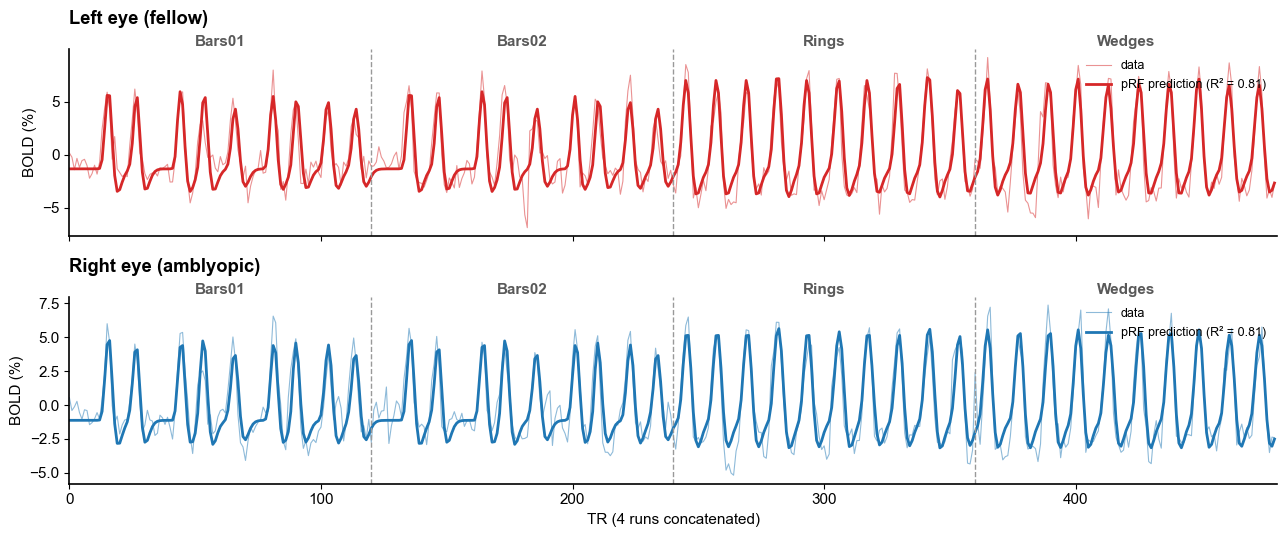

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
for ax, e in zip(axes, eyes):
    ax.plot(t, data[e], color=eye_colors[e], lw=0.8, alpha=0.5, label='data')
    ax.plot(t, pred[e], color=eye_colors[e], lw=2, label='pRF prediction (R² = {:.2f})'.format(deriv[e][0]['prf_rsq'][vertex]))
    ax.set_ylabel('BOLD (%)')
    ax.set_title(eye_labels[e], loc='left', fontweight='bold', pad=18)
    ax.legend(loc='upper right', frameon=False, fontsize=9)
    run_axes(ax)
axes[-1].set_xlabel('TR (4 runs concatenated)')
plt.tight_layout()
save(fig, 'step1_data_and_fit')

## Step 2 — The two predictions have arbitrary scales

Plotted together, the two predictions differ in shape (slightly different pRFs) **and** in scale. Their scale comes from the prfmodel amplitude, which is not normalised (it depends on the pixel size of the stimulus, on σ and on the exponent n), so it cannot be used to compare the eyes directly.

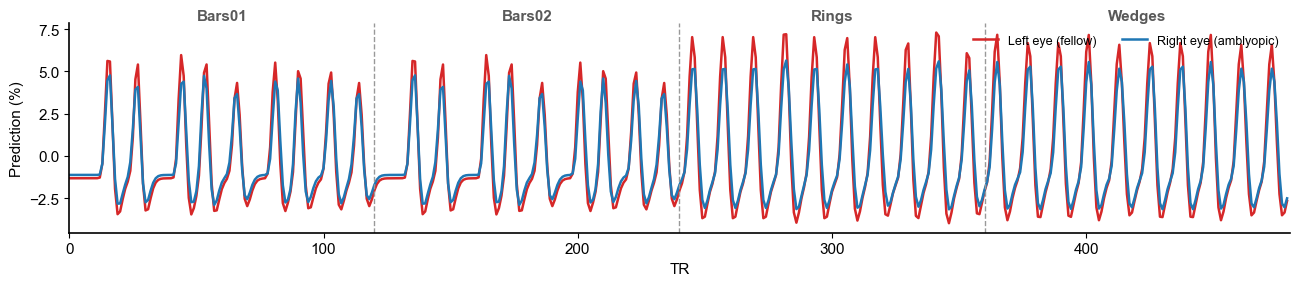

In [6]:
fig, ax = plt.subplots(figsize=(13, 3))
for e in eyes:
    ax.plot(t, pred[e], color=eye_colors[e], lw=1.8, label=eye_labels[e])
ax.set_ylabel('Prediction (%)')
ax.legend(loc='upper right', frameon=False, fontsize=9, ncol=2)
run_axes(ax)
ax.set_xlabel('TR')
plt.tight_layout()
save(fig, 'step2_predictions')

## Step 3 — Each prediction is z-scored once on the whole concatenation

`z = (prediction − mean) / standard deviation`, computed over the 4 runs together. Only the temporal **shape** is kept, and both eyes get the same weight in the next step. One single scaling factor per eye for the whole concatenation (not run by run).

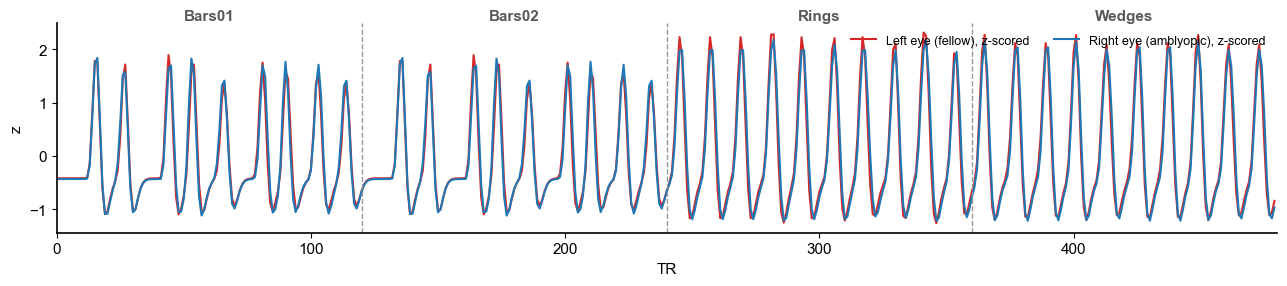

Correlation between the two predictions: r = 0.981


In [7]:
z = {e: (pred[e] - pred[e].mean()) / pred[e].std() for e in eyes}
fig, ax = plt.subplots(figsize=(13, 3))
for e in eyes:
    ax.plot(t, z[e], color=eye_colors[e], lw=1.5, label=eye_labels[e] + ', z-scored')
ax.set_ylabel('z')
ax.legend(loc='upper right', frameon=False, fontsize=9, ncol=2)
run_axes(ax)
ax.set_xlabel('TR')
plt.tight_layout()
save(fig, 'step3_zscored_predictions')
print('Correlation between the two predictions: r = {:.3f}'.format(np.corrcoef(pred['L'], pred['R'])[0, 1]))

## Step 4 — Common regressor = mean of the two z-scored predictions

Both eyes will be measured with **the same** regressor: a difference of β between the eyes can then only come from a difference of response, not from a difference of pRF fit. Orange: mean of the regressor in each run; it differs between runs because the stimuli differ (the vertex is stimulated more or less often).

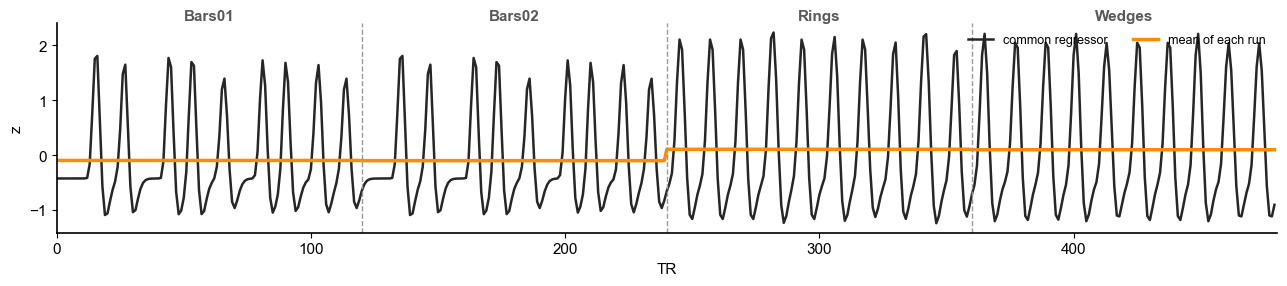

In [8]:
common = (z['L'] + z['R']) / 2
run_mean = np.repeat(common.reshape(n_runs, TRs).mean(axis=1), TRs)
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(t, common, color='0.15', lw=1.8, label='common regressor')
ax.plot(t, run_mean, color='darkorange', lw=2.5, label='mean of each run')
ax.set_ylabel('z')
ax.legend(loc='upper right', frameon=False, fontsize=9, ncol=2)
run_axes(ax)
ax.set_xlabel('TR')
plt.tight_layout()
save(fig, 'step4_common_regressor')

## Step 5 — One baseline per run

The data are in percent signal change computed run by run, so each run of the data is centred on 0, but the regressor is not (step 4). The mean of each run is removed from the regressor **and** from the data: each run then has its own baseline. This is exactly a GLM with one constant per run. Top: regressor; bottom: data of each eye, run means removed.

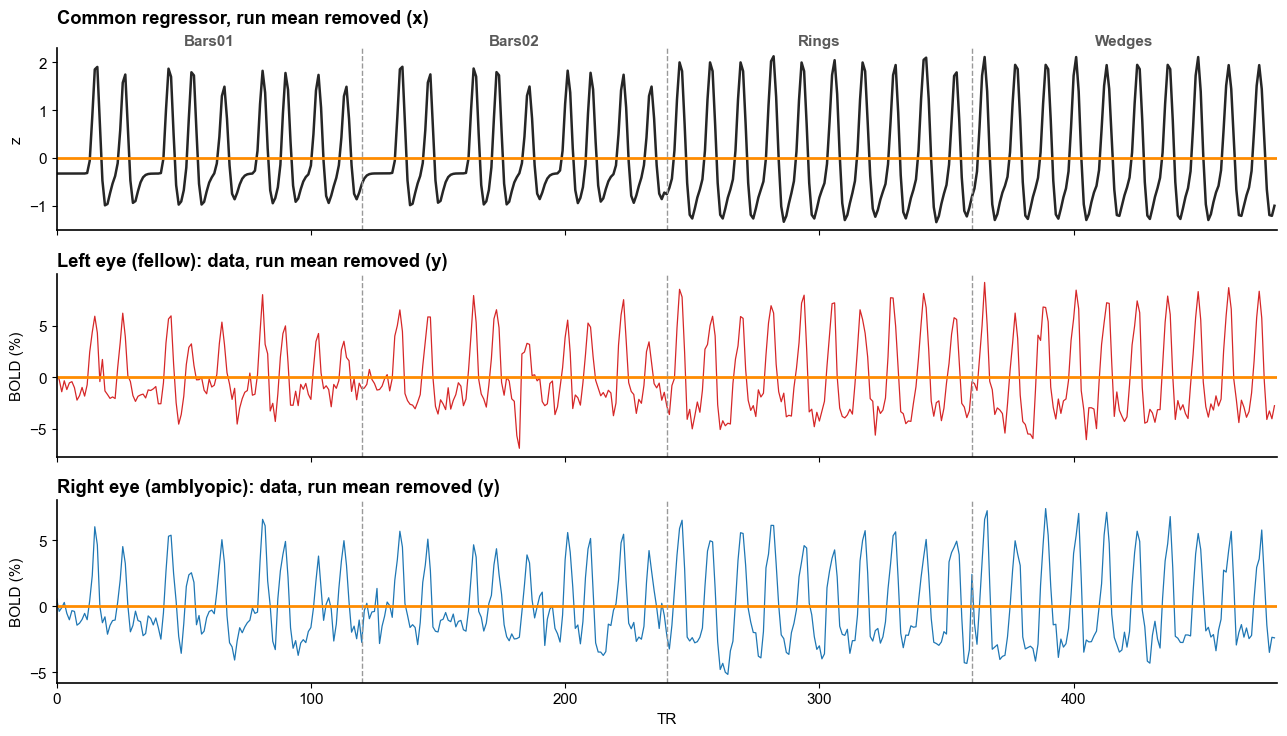

In [9]:
x = common - run_mean
y = {e: data[e] - np.repeat(data[e].reshape(n_runs, TRs).mean(axis=1), TRs) for e in eyes}
fig, axes = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
axes[0].plot(t, x, color='0.15', lw=1.8)
axes[0].axhline(0, color='darkorange', lw=2)
axes[0].set_ylabel('z')
axes[0].set_title('Common regressor, run mean removed (x)', loc='left', fontweight='bold', pad=18)
run_axes(axes[0])
for ax, e in zip(axes[1:], eyes):
    ax.plot(t, y[e], color=eye_colors[e], lw=0.9)
    ax.axhline(0, color='darkorange', lw=2)
    ax.set_ylabel('BOLD (%)')
    ax.set_title('{}: data, run mean removed (y)'.format(eye_labels[e]), loc='left', fontweight='bold')
    run_axes(ax, names=False)
axes[-1].set_xlabel('TR')
plt.tight_layout()
save(fig, 'step5_one_baseline_per_run')

## Step 6 — GLM of each eye on the same regressor

For each eye, all runs together: `β = Σ x·y / Σ x²` = the factor by which the regressor must be scaled to best fit the data of that eye (least squares). `SE = √[(Σy² − β·Σxy) / (dof · Σx²)]`, `dof = n_TR − n_runs − 1`. β is in % signal per standard deviation of the regressor; since the regressor is the same for both eyes, the βs of the two eyes are directly comparable.

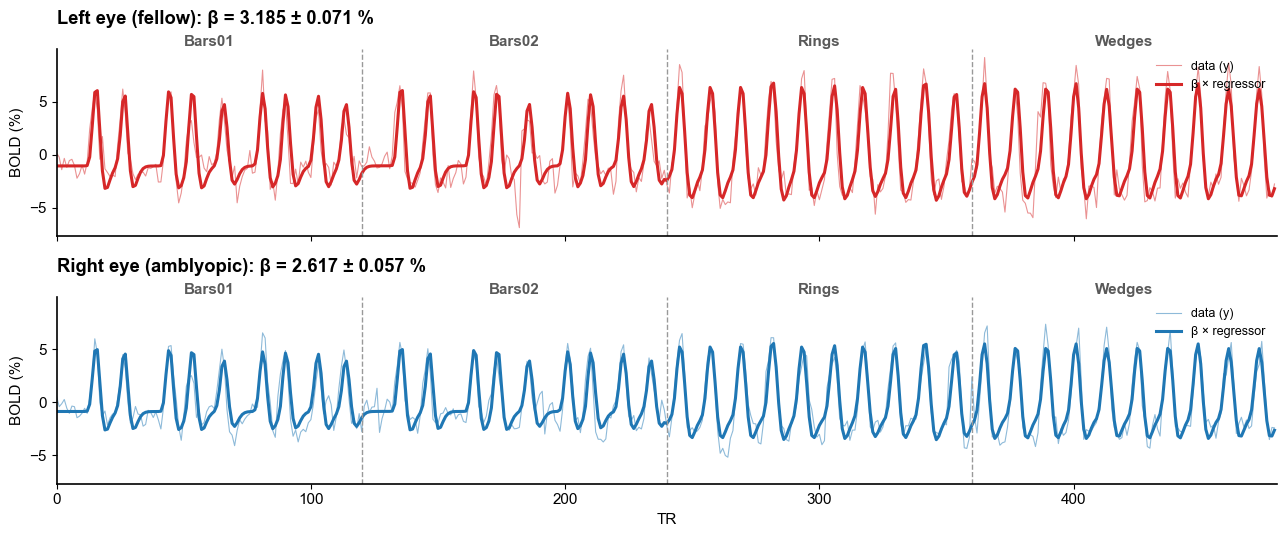

In [10]:
sxx = np.sum(x ** 2)
dof = n_tr - n_runs - 1
beta, se = {}, {}
for e in eyes:
    sxy = np.sum(x * y[e])
    beta[e] = sxy / sxx
    se[e] = np.sqrt(max(np.sum(y[e] ** 2) - beta[e] * sxy, 0) / dof / sxx)

fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, e in zip(axes, eyes):
    ax.plot(t, y[e], color=eye_colors[e], lw=0.8, alpha=0.5, label='data (y)')
    ax.plot(t, beta[e] * x, color=eye_colors[e], lw=2.2, label='β × regressor')
    ax.set_ylabel('BOLD (%)')
    ax.set_title('{}: β = {:.3f} ± {:.3f} %'.format(eye_labels[e], beta[e], se[e]), loc='left', fontweight='bold', pad=18)
    ax.legend(loc='upper right', frameon=False, fontsize=9)
    run_axes(ax)
axes[-1].set_xlabel('TR')
plt.tight_layout()
save(fig, 'step6_glm_fit')

## Step 7 — Result for this vertex

β of each eye (± SE), OD index `(β_L − β_R) / (β_L + β_R)` and `z = (β_L − β_R) / √(SE_L² + SE_R²)`. Last check: the same values read from the OD image written by `make_od_img.py` (they should be identical).

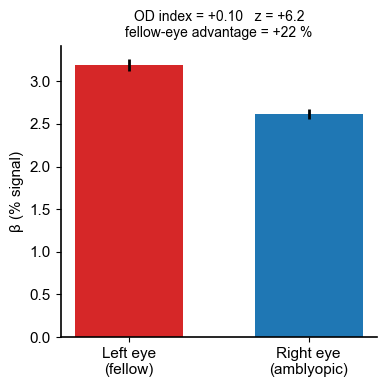

,this notebook,make_od_img.py
beta_L,3.185496,3.185496
beta_R,2.617099,2.617099
SE_L,0.070716,0.070716
SE_R,0.057317,0.057317
OD index (L-R),0.097956,0.097956
z (L-R),6.244258,6.244257


In [11]:
od = (beta['L'] - beta['R']) / (beta['L'] + beta['R']) if (beta['L'] > 0) & (beta['R'] > 0) else np.nan
z_od = (beta['L'] - beta['R']) / np.sqrt(se['L'] ** 2 + se['R'] ** 2)
adv = 100 * (beta[fe] / beta['L' if fe == 'R' else 'R'] - 1)

fig, ax = plt.subplots(figsize=(4, 4))
for i, e in enumerate(eyes):
    ax.bar(i, beta[e], yerr=se[e], color=eye_colors[e], width=0.6, capsize=0, error_kw=dict(lw=2))
ax.set_xticks([0, 1])
ax.set_xticklabels([eye_labels[e].replace(' (', '\n(') for e in eyes])
ax.set_ylabel('β (% signal)')
ax.set_title('OD index = {:+.2f}   z = {:+.1f}\nfellow-eye advantage = {:+.0f} %'.format(od, z_od, adv), fontsize=10)
plt.tight_layout()
save(fig, 'step7_result')

# Check against the OD image of make_od_img.py
od_fn = file_spec.format(pp_dir, subject, 'prfmodel/prf_derivatives', subject, task, '', hemi, 'prf-css_od')
_, od_img = load_surface(od_fn)
check = pd.DataFrame({'this notebook': [beta['L'], beta['R'], se['L'], se['R'], od, z_od],
                      'make_od_img.py': [od_img[maps_names_css_od.index(n), v_h] for n in
                                         ['od_beta_le', 'od_beta_re', 'od_se_le', 'od_se_re', 'od_le_re', 'od_z_le_re']]},
                     index=['beta_L', 'beta_R', 'SE_L', 'SE_R', 'OD index (L-R)', 'z (L-R)'])
check